# Wasserstein distance: moving probability mass
This DRP lesson connects exact mathematics to tiny, reproducible computations.
Read the explanations, run each cell, then change one parameter at a time.
All data are synthetic. No GPU, training, or dataset download is needed.

We distinguish the ground distance between points, the distance between
probability laws, and a numerical estimate from finite samples. Throughout,
$\mathcal N(\mu,\sigma^2)$ uses **variance** as its second parameter.
Python's `rng.normal(mu, sigma, n)` instead takes the **standard deviation**.

## 1. Setup
Run in this lesson folder, or run the script from any folder. Figures are
saved as vector PDF and PNG, and measured results as JSON and LaTeX.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm, wasserstein_distance
from scipy.spatial.distance import cdist
from ot_tools import (gaussian_distances, empirical_wp_equal, exact_ot,
                      sinkhorn_log, mmd2_biased, image_measure, signature_level2, signature_level3)

ROOT = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
(ROOT / 'figures').mkdir(exist_ok=True)
(ROOT / 'results').mkdir(exist_ok=True)
rng = np.random.default_rng(2026)
BLUE, ORANGE, GREEN = '#2266B3', '#D6603C', '#25857C'
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120,
                     'axes.prop_cycle': plt.cycler(color=[BLUE, ORANGE, GREEN])})
metrics = {}

def savefig(name):
    plt.savefig(ROOT / 'figures' / f'{name}.pdf', bbox_inches='tight')
    plt.savefig(ROOT / 'figures' / f'{name}.png', bbox_inches='tight', dpi=160)
    if "__file__" not in globals():
        plt.show()
    plt.close()

print('Python', platform.python_version(), '| NumPy', np.__version__,
      '| SciPy', scipy.__version__, '| Matplotlib', matplotlib.__version__)

Python 3.14.2 | NumPy 2.5.4 | SciPy 1.18.1 | Matplotlib 3.11.2


## 2. Point masses and three ways to compare distributions
A point mass $\delta_c$ puts probability 1 at location $c$.
Thus a sample from $P=\delta_0$ is always 0 and a sample from
$Q=\delta_a$ is always $a$. The parameter $a$ is a location, not a mass.

**Wasserstein:** a transport plan $\pi_{ij}$ specifies how much mass moves
from $x_i$ to $y_j$, preserving all source and target masses. For finite
discrete distributions and $1\leq p<\infty$,
$$W_p(P,Q)=\left(\min_{\text{valid }\pi}\sum_{i,j}\pi_{ij}|x_i-y_j|^p\right)^{1/p}.$$
Multiply each moved mass by distance to the power $p$, add, minimize,
and take the $p$th root. For our point masses there is only one valid plan:
move mass 1 from 0 to $a$. Hence $W_p=(1\cdot|0-a|^p)^{1/p}=|a|$.
For $a=3$, $W_1=1\cdot3=3$ and $W_2=\sqrt{1\cdot3^2}=3$.
Negative $a$ also gives a positive travel distance.

**Total variation:** for discrete laws, use
$$\operatorname{TV}(P,Q)=\tfrac12\sum_z|P(\{z\})-Q(\{z\})|.$$
If $a\ne0$, the distinct locations 0 and $a$ give
$\operatorname{TV}=\tfrac12(|1-0|+|0-1|)=1$.
The factor 1/2 avoids counting the missing mass twice. TV compares
probabilities at each location and does not use the distance between locations.

**KL divergence:** writing $p_z=P(\{z\})$ and $q_z=Q(\{z\})$,
$$D_{KL}(P\Vert Q)=\sum_{z:p_z>0}p_z\log(p_z/q_z).$$
A term with $p_z>0$ and $q_z=0$ is $+\infty$ by definition.
This agrees with $\log(1/\varepsilon)\to+\infty$ as $\varepsilon\downarrow0$.
Here $p_0=1$ and $q_0=0$ for $a\ne0$, so KL is infinite.
KL is a divergence, not a metric, and is generally asymmetric.

At $a=0$, the laws coincide and all three quantities equal 0.
“Discrepancy” is just a general term for a numerical measure of difference,
not a separate quantity. The plots below name their quantities explicitly.
Wasserstein has position units, while TV is dimensionless. Their numerical
sizes do not rank their usefulness. Infinite KL cannot be drawn as a finite curve.

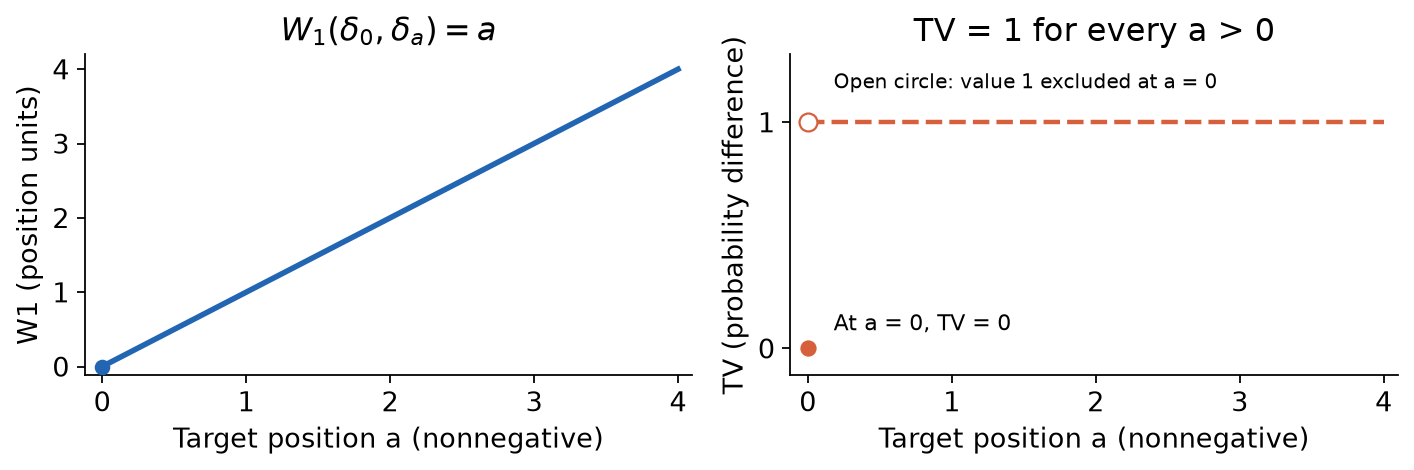

In [2]:
shifts = np.linspace(0, 4, 101)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.1))
axes[0].plot(shifts, shifts, color=BLUE, lw=2.5)
axes[0].scatter([0], [0], color=BLUE, zorder=3)
axes[0].set(xlabel='Target position a (nonnegative)', ylabel='W1 (position units)',
            title=r'$W_1(\delta_0,\delta_a)=a$', xlim=(-.12, 4.1), ylim=(-.12, 4.2))
axes[1].plot([0, 4], [1, 1], '--', color=ORANGE, lw=2)
axes[1].scatter([0], [1], facecolors='white', edgecolors=ORANGE, s=65, zorder=3)
axes[1].scatter([0], [0], color=ORANGE, s=40, zorder=3)
axes[1].set(xlabel='Target position a (nonnegative)', ylabel='TV (probability difference)',
            title='TV = 1 for every a > 0', xlim=(-.12, 4.1), ylim=(-.12, 1.3), yticks=[0, 1])
axes[1].annotate('Open circle: value 1 excluded at a = 0', xy=(0, 1),
                 xytext=(.18, 1.15), fontsize=9)
axes[1].text(.18, .08, 'At a = 0, TV = 0', fontsize=10)
fig.tight_layout()
savefig('point_mass')



## 3. Couplings and the definition
A coupling $\pi$ is a joint law of $(X,Y)$ with $X\sim P$ and $Y\sim Q$.
It describes how source mass is assigned to target mass. It can split mass.
For distributions with finite p-th moments on a metric space $(\mathcal X,d)$,
$$W_p(P,Q)=\left[\inf_{\pi\in\Pi(P,Q)}\int d(x,y)^p\,d\pi(x,y)\right]^{1/p}.$$
For $p=1$ this is minimum average travel distance. For $p=2$ it is the
minimum root mean squared travel distance. The root is essential.
An independent coupling $P\otimes Q$ is feasible but usually not optimal.
A deterministic map $Y=T(X)$ is more restrictive: an atom may need to split.

### A transport plan we can check by hand
$P=0.5\delta_0+0.5\delta_2$, $Q=0.25\delta_1+0.75\delta_3$.
The sorted plan sends 0.25 from 0 to 1, 0.25 from 0 to 3,
and 0.5 from 2 to 3. Its $W_1$ cost is $0.25+0.75+0.5=1.5$.
The same plan is optimal for squared cost, giving $W_2=\sqrt3$.

Plan (rows: source; columns: target):
 [[0.25 0.25]
 [0.   0.5 ]]
W1 = 1.500000; W2 squared = 3.000000; W2 = 1.732051
Row sums: [0.5 0.5] Column sums: [0.25 0.75]


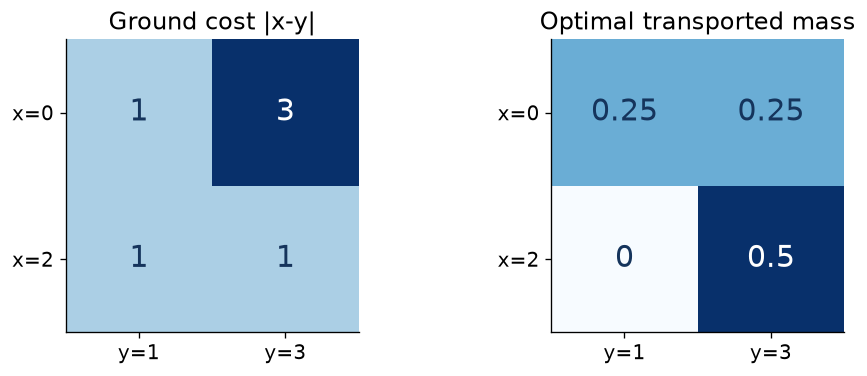

In [3]:
x, y = np.array([0., 2.]), np.array([1., 3.])
a, b = np.array([.5, .5]), np.array([.25, .75])
w1, plan, cost = exact_ot(x, y, a, b, p=1)
w2, plan2, cost2 = exact_ot(x, y, a, b, p=2)
print('Plan (rows: source; columns: target):\n', plan)
print(f'W1 = {w1:.6f}; W2 squared = {w2**2:.6f}; W2 = {w2:.6f}')
print('Row sums:', plan.sum(1), 'Column sums:', plan.sum(0))
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.3))
for ax, matrix, title in zip(axes, [cost, plan], ['Ground cost |x-y|', 'Optimal transported mass']):
    ax.imshow(matrix, cmap='Blues', vmin=0)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{matrix[i,j]:g}', ha='center', va='center',
                    color='white' if matrix[i,j] > matrix.max()*.6 else '#15345C', fontsize=18)
    ax.set_xticks([0, 1], ['y=1', 'y=3']); ax.set_yticks([0, 1], ['x=0', 'x=2'])
    ax.set_title(title)
plt.tight_layout(); savefig('discrete_plan')
metrics['discrete'] = {'w1': w1, 'w2': w2, 'plan': plan.tolist()}

## 4. One dimension: match quantiles
Write $F^{-1}(u)=\inf\{x:F(x)\geq u\}$. Matching equal quantiles gives
$$W_p^p(P,Q)=\int_0^1 |F_P^{-1}(u)-F_Q^{-1}(u)|^p\,du.$$
For $p=1$, also $W_1=\int_{\mathbb R}|F_P(x)-F_Q(x)|\,dx$.
Sorting implements this principle for equally weighted empirical samples.
When sizes or weights differ, quantile intervals have different masses:
naive pairwise subtraction is invalid. SciPy handles this for 1D W1.

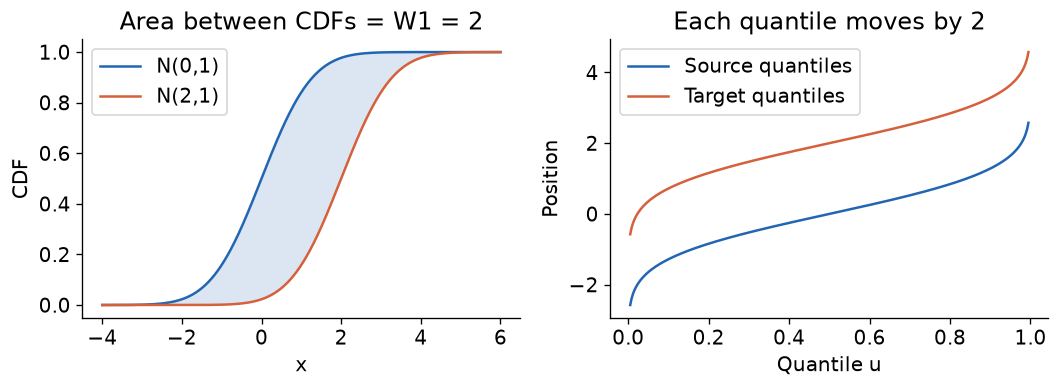

In [4]:
grid = np.linspace(-4, 6, 500)
u = np.linspace(.005, .995, 300)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(grid, norm.cdf(grid), label='N(0,1)')
axes[0].plot(grid, norm.cdf(grid, loc=2), label='N(2,1)')
axes[0].fill_between(grid, norm.cdf(grid), norm.cdf(grid, loc=2), alpha=.16)
axes[0].set(xlabel='x', ylabel='CDF', title='Area between CDFs = W1 = 2')
axes[0].legend()
axes[1].plot(u, norm.ppf(u), label='Source quantiles')
axes[1].plot(u, 2+norm.ppf(u), label='Target quantiles')
axes[1].set(xlabel='Quantile u', ylabel='Position', title='Each quantile moves by 2')
axes[1].legend(); plt.tight_layout(); savefig('quantiles')

## 5. Analytic Gaussian distances
Let $X=\mu_1+\sigma_1 Z$, $Y=\mu_2+\sigma_2 Z$, where $Z\sim N(0,1)$.
Using the **same** Z matches equal quantiles and is optimal in one dimension.
Set $\Delta\mu=\mu_2-\mu_1$ and $\Delta\sigma=\sigma_2-\sigma_1$.
$$W_2^2=E[(\Delta\mu+\Delta\sigma Z)^2]
=(\Delta\mu)^2+(\Delta\sigma)^2.$$
The cross term vanishes because $E[Z]=0$, and $E[Z^2]=1$.
With $m=|\Delta\mu|$, $s=|\Delta\sigma|$,
$$W_1=s\sqrt{2/\pi}e^{-m^2/(2s^2)}+m[2\Phi(m/s)-1],\quad s>0.$$
If $s=0$, $W_1=m$. If $m=0$, $W_1=s\sqrt{2/\pi}$.
This follows by integrating $|m+sZ|$ on either side of $Z=-m/s$.
Analytic means a formula derived for the population laws, with no random
sampling or numerical transport optimization required. A computer can evaluate it.

The cases below compare N(0,1) against N(2,1), N(0,4), and N(2,4).
The corresponding target standard deviations are 1, 2, and 2.

Mean changes       W1: formula 2.0000, sample 2.0292   W2: formula 2.0000, sample 2.0294


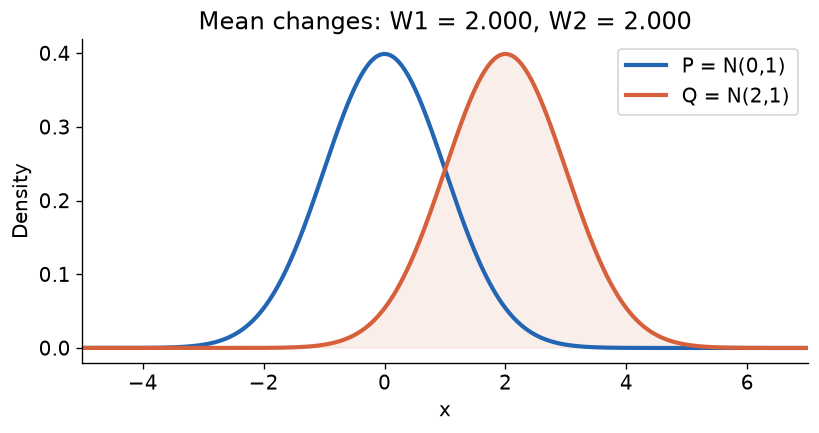

Variance changes   W1: formula 0.7979, sample 0.8091   W2: formula 1.0000, sample 1.0059


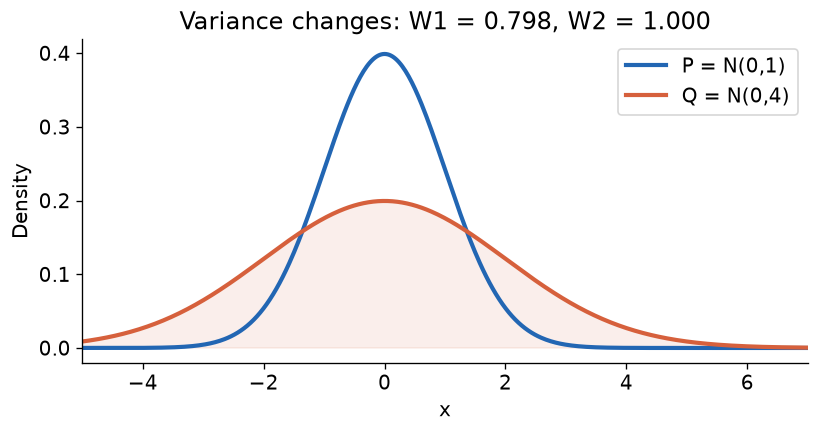

Both change        W1: formula 2.0170, sample 2.0136   W2: formula 2.2361, sample 2.2152


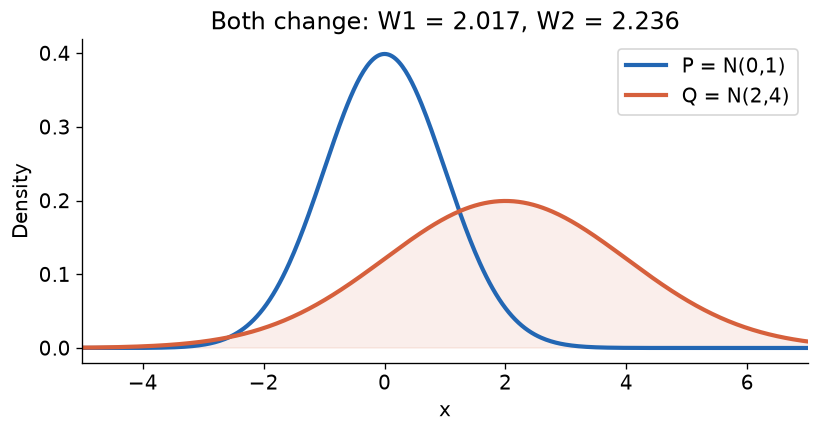

In [5]:
cases = [('Mean changes', 2., 1.), ('Variance changes', 0., 2.), ('Both change', 2., 2.)]
metrics['gaussians'] = []
for label, mu, sigma in cases:
    analytic1, analytic2 = gaussian_distances(0, 1, mu, sigma)
    sample_x = rng.normal(0, 1, 4000)
    sample_y = rng.normal(mu, sigma, 4000)
    measured1 = wasserstein_distance(sample_x, sample_y)
    measured2 = empirical_wp_equal(sample_x, sample_y)
    row = dict(case=label, mu=mu, sigma=sigma, w1=analytic1, w2=analytic2,
               empirical_w1=measured1, empirical_w2=measured2)
    metrics['gaussians'].append(row)
    print(f'{label:18s} W1: formula {analytic1:.4f}, sample {measured1:.4f}'
          f'   W2: formula {analytic2:.4f}, sample {measured2:.4f}')
    grid = np.linspace(-7, 9, 600)
    plt.figure(figsize=(7.8, 3.5))
    plt.plot(grid, norm.pdf(grid), lw=2.5, label='P = N(0,1)')
    plt.plot(grid, norm.pdf(grid, mu, sigma), lw=2.5, label=f'Q = N({mu:g},{sigma**2:g})')
    plt.fill_between(grid, norm.pdf(grid, mu, sigma), alpha=.10, color=ORANGE)
    plt.xlim(-5, 7); plt.xlabel('x'); plt.ylabel('Density'); plt.legend()
    plt.title(f'{label}: W1 = {analytic1:.3f}, W2 = {analytic2:.3f}')
    savefig('gaussian_' + label.split()[0].lower())

### The Gaussian transport map and interpolation
For $\sigma_1>0$, $T(x)=\mu_2+(\sigma_2/\sigma_1)(x-\mu_1)$ pushes P to Q.
Along $X_t=(1-t)X+tT(X)$ the mean interpolates linearly, as does the
**standard deviation**. This displacement interpolation moves mass.
In contrast, $(1-t)P+tQ$ mixes densities and can have two peaks.

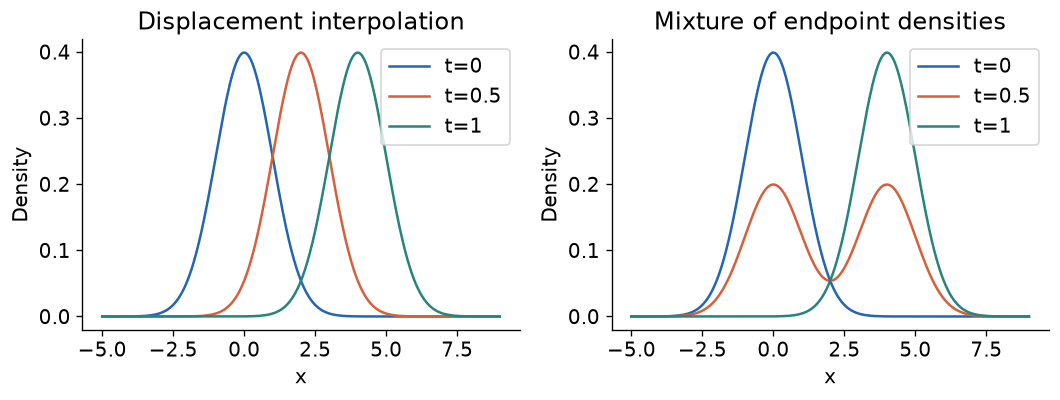

In [6]:
grid = np.linspace(-5, 9, 600)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for t in [0, .5, 1]:
    axes[0].plot(grid, norm.pdf(grid, 4*t, 1), label=f't={t:g}')
    axes[1].plot(grid, (1-t)*norm.pdf(grid)+t*norm.pdf(grid, 4), label=f't={t:g}')
for ax in axes:
    ax.set(xlabel='x', ylabel='Density'); ax.legend()
axes[0].set_title('Displacement interpolation')
axes[1].set_title('Mixture of endpoint densities')
plt.tight_layout(); savefig('interpolation')

## 6. Sorting, weights, and sample uncertainty
`wasserstein_distance(x,y)` computes empirical **W1**, not W2.
Each array supplies observations, not histogram heights.
To supply histogram masses use bin locations as values and masses as weights.
Representing a continuous histogram by bin centers is a discretization.
The equal-size W2 sorting formula below is exact for those empirical laws.
It still estimates a population distance with sampling error.

Sorted W1: 1.3333333333333335
Sorted W2: 1.4142135623730951
Weighted W1: 1.5
Unequal sample sizes: 0.5


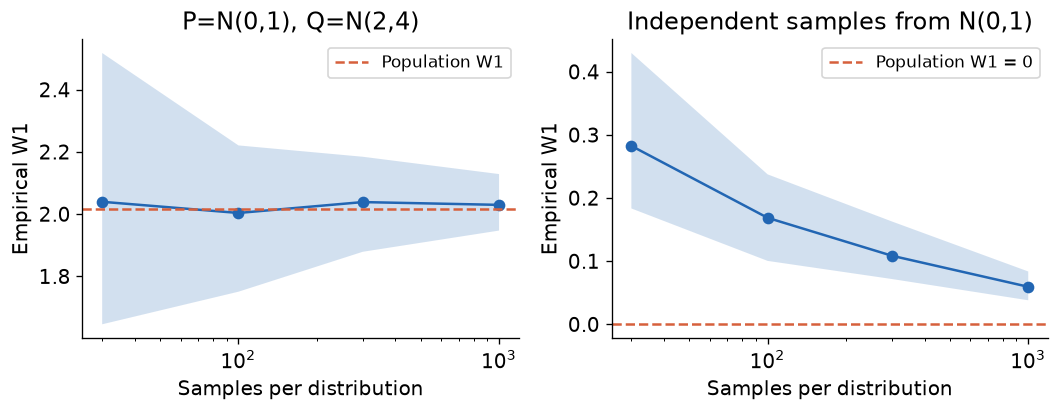

Shading: 10th to 90th percentiles of 80 repetitions; not confidence intervals.


In [7]:
x_small = np.array([0., 1., 3.])
y_small = np.array([1., 2., 5.])
print('Sorted W1:', wasserstein_distance(x_small, y_small))
print('Sorted W2:', empirical_wp_equal(x_small, y_small, p=2))
print('Weighted W1:', wasserstein_distance([0, 2], [1, 3],
                                         u_weights=[.5, .5], v_weights=[.25, .75]))
print('Unequal sample sizes:', wasserstein_distance([0, 1], [0, 1, 2]))

sizes = [30, 100, 300, 1000]
repeats = 80
errors, same_law = [], []
for n in sizes:
    distances, baseline = [], []
    for _ in range(repeats):
        x = rng.normal(size=n)
        distances.append(wasserstein_distance(x, rng.normal(2, 2, n)))
        baseline.append(wasserstein_distance(x, rng.normal(size=n)))
    errors.append(np.asarray(distances))
    same_law.append(np.asarray(baseline))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, values, title in zip(axes, [errors, same_law],
                            ['P=N(0,1), Q=N(2,4)', 'Independent samples from N(0,1)']):
    means = np.array([v.mean() for v in values])
    low, high = np.array([np.quantile(v, [.1, .9]) for v in values]).T
    ax.plot(sizes, means, 'o-'); ax.fill_between(sizes, low, high, alpha=.2)
    ax.set(xscale='log', xlabel='Samples per distribution', ylabel='Empirical W1', title=title)
axes[0].axhline(gaussian_distances(0,1,2,2)[0], color=ORANGE, ls='--', label='Population W1')
axes[1].axhline(0, color=ORANGE, ls='--', label='Population W1 = 0')
for ax in axes: ax.legend(fontsize=10)
plt.tight_layout(); savefig('sampling')
print('Shading: 10th to 90th percentiles of 80 repetitions; not confidence intervals.')

## 7. Computational optimal transport and Sinkhorn
The LP minimizes $\sum_{ij}\pi_{ij} C_{ij}$ subject to nonnegative entries,
row sums a, and column sums b. Set $C_{ij}=\|x_i-y_j\|^p$, then take
the p-th root of its optimal value. `exact_ot` exposes the small SciPy LP.
Dense costs require n*m entries, so large images should not be passed
directly to this teaching solver. Specialized solvers, multiscale methods,
entropic OT, and sliced Wasserstein help in larger problems.

Sinkhorn solves a **different**, regularized problem:
$$OT_\epsilon(a,b)=\min_\pi\langle\pi,C\rangle+
\epsilon\sum_{ij}\pi_{ij}(\log\pi_{ij}-1).$$
For positive masses its optimizer is diag(u) exp(-C/epsilon) diag(v).
Alternately enforce row and column sums. Our helper works in log space
and checks the marginal residual, avoiding silent underflow/convergence errors.
We report transport cost and full objective separately. Neither is exact Wp.
A debiased Sinkhorn divergence is
$S_\epsilon(P,Q)=OT_\epsilon(P,Q)-\frac12OT_\epsilon(P,P)-\frac12OT_\epsilon(Q,Q)$.
Always use the same cost, epsilon, and entropy convention in all three terms.

epsilon=0.2: transport=5.340050, objective=4.734823, S_epsilon=5.196060, self transport=0.009698, residual=4.5e-12
epsilon=0.7: transport=5.397433, objective=3.201000, S_epsilon=5.015089, self transport=0.256599, residual=7.2e-11
epsilon=2: transport=5.708098, objective=-1.073292, S_epsilon=4.864846, self transport=0.668769, residual=5.6e-17


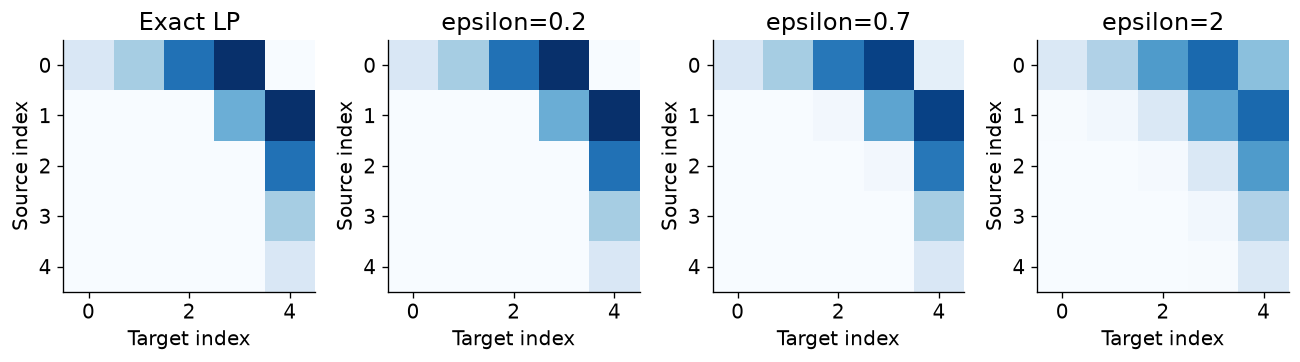

In [8]:
support = np.arange(5, dtype=float)[:, None]
a = np.array([.45, .30, .15, .07, .03])
b = a[::-1].copy()
exact, exact_plan, C = exact_ot(support, support, a, b, p=2)
epsilons = [.2, .7, 2.0]
plans, sinkrows = [exact_plan], []
for epsilon in epsilons:
    pi, info = sinkhorn_log(a, b, C, epsilon)
    _, aa = sinkhorn_log(a, a, C, epsilon)
    _, bb = sinkhorn_log(b, b, C, epsilon)
    divergence = info['objective'] - .5*(aa['objective']+bb['objective'])
    sinkrows.append(dict(epsilon=epsilon, **info, divergence=divergence,
                         self_transport_cost=aa['transport_cost']))
    plans.append(pi)
    print(f"epsilon={epsilon:g}: transport={info['transport_cost']:.6f}, "
          f"objective={info['objective']:.6f}, S_epsilon={divergence:.6f}, "
          f"self transport={aa['transport_cost']:.6f}, residual={info['marginal_error']:.1e}")
fig, axes = plt.subplots(1, 4, figsize=(11, 3.1))
for ax, pi, label in zip(axes, plans, ['Exact LP'] + [f'epsilon={e:g}' for e in epsilons]):
    ax.imshow(pi, vmin=0, vmax=max(z.max() for z in plans), cmap='Blues')
    ax.set(title=label, xlabel='Target index', ylabel='Source index')
plt.tight_layout(); savefig('sinkhorn')
metrics['sinkhorn'] = dict(exact_w2_squared=exact**2, runs=sinkrows)

## 8. Two images: intensity distribution or spatial mass?
These 7x7 images each contain a 2x2 bright patch. The second patch moves
three columns right. Their lists of intensities are identical up to order.
Intensity-histogram W1 is therefore zero: it discards location.

For spatial transport, place normalized nonnegative intensity at each pixel
coordinate. Euclidean ground distance has units of pixels. Every unit of
mass can move right by 3, so W1 <= 3. The mean x-coordinate changes by 3,
giving W1 >= 3. Hence W1 = W2 = 3 for this translated patch.
Normalizing discards total brightness. Signed or all-zero images require
a different representation. Color/feature distributions answer other questions.
A distribution of whole images is different again: one image is one sample.

Intensity W1 = 0; spatial W1 = 3 pixels; W2 = 3 pixels


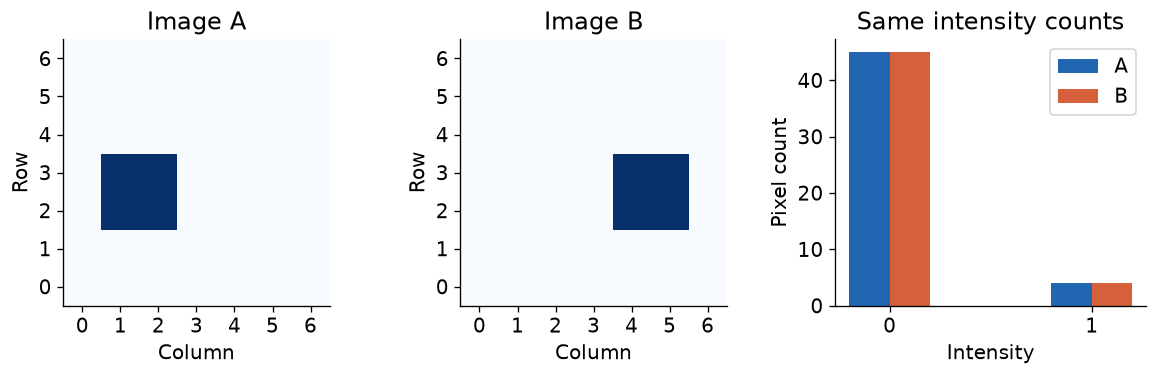

In [9]:
image_a = np.zeros((7, 7)); image_a[2:4, 1:3] = 1
image_b = np.zeros((7, 7)); image_b[2:4, 4:6] = 1
xy_a, mass_a = image_measure(image_a)
xy_b, mass_b = image_measure(image_b)
intensity_w1 = wasserstein_distance(image_a.ravel(), image_b.ravel())
spatial_w1, image_plan, _ = exact_ot(xy_a, xy_b, mass_a, mass_b, p=1)
spatial_w2, _, _ = exact_ot(xy_a, xy_b, mass_a, mass_b, p=2)
print(f'Intensity W1 = {intensity_w1:g}; spatial W1 = {spatial_w1:g} pixels; W2 = {spatial_w2:g} pixels')
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for ax, img, label in zip(axes[:2], [image_a, image_b], ['Image A', 'Image B']):
    ax.imshow(img, cmap='Blues', vmin=0, vmax=1, origin='lower')
    ax.set(xlabel='Column', ylabel='Row', title=label, xticks=range(7), yticks=range(7))
axes[2].hist([image_a.ravel(), image_b.ravel()], bins=[-.25,.25,.75,1.25], label=['A','B'])
axes[2].set(xlabel='Intensity', ylabel='Pixel count', title='Same intensity counts', xticks=[0,1])
axes[2].legend(); plt.tight_layout(); savefig('images')
metrics['images'] = dict(intensity_w1=intensity_w1, spatial_w1=spatial_w1, spatial_w2=spatial_w2)

## 9. A time series is more than a value histogram
A=(0,0,1,1), B=(0,1,0,1) have identical amplitude distributions, but
different ordering. `wasserstein_distance(A,B)` is zero and ignores time.
One option is to place equal mass on points $(\lambda t_i,x_i)$.
The choice of lambda trades time mismatch against amplitude mismatch.
This compares point clouds and permits arbitrary matchings. It does not
enforce a chronological alignment as dynamic time warping does.

Amplitude W1: 0.0
Time scale lambda=0: point-cloud W1=0.000000
Time scale lambda=0.25: point-cloud W1=0.125000
Time scale lambda=1: point-cloud W1=0.500000
Time scale lambda=4: point-cloud W1=0.500000


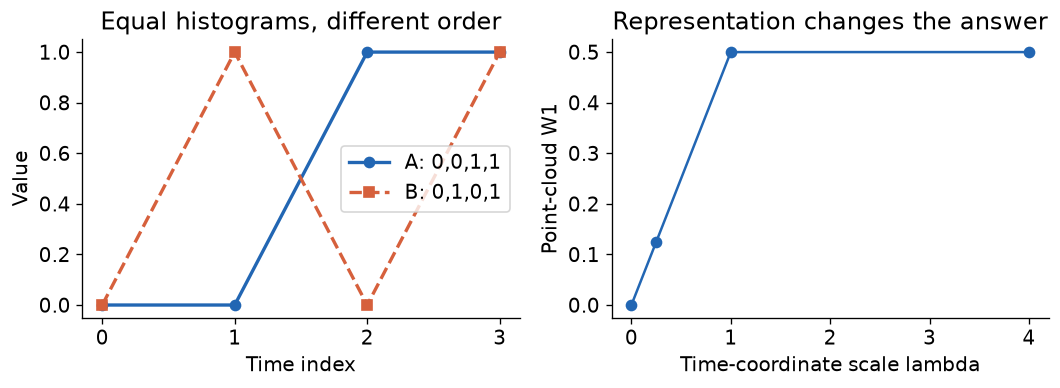

In [10]:
series_a = np.array([0., 0., 1., 1.])
series_b = np.array([0., 1., 0., 1.])
t = np.arange(4, dtype=float)
print('Amplitude W1:', wasserstein_distance(series_a, series_b))
time_rows = []
for weight in [0., .25, 1., 4.]:
    cloud_a, cloud_b = np.c_[weight*t, series_a], np.c_[weight*t, series_b]
    distance, _, _ = exact_ot(cloud_a, cloud_b)
    time_rows.append(dict(time_weight=weight, w1=distance))
    print(f'Time scale lambda={weight:g}: point-cloud W1={distance:.6f}')
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
axes[0].plot(t, series_a, 'o-', label='A: 0,0,1,1', lw=2)
axes[0].plot(t, series_b, 's--', label='B: 0,1,0,1', lw=2)
axes[0].set(xlabel='Time index', ylabel='Value', title='Equal histograms, different order', xticks=t)
axes[0].legend()
axes[1].plot([r['time_weight'] for r in time_rows], [r['w1'] for r in time_rows], 'o-')
axes[1].set(xlabel='Time-coordinate scale lambda', ylabel='Point-cloud W1', title='Representation changes the answer')
plt.tight_layout(); savefig('time_series')
metrics['time_series'] = time_rows

### Windows and distributions of complete paths
Windows (x_t,x_{t+1}) retain some local dependence. They can overlap,
so do not assume they are independent samples in a statistical test.
If we have many real and generated series, each *whole path* can be one
vector-valued sample. Euclidean/RMS path distance then preserves grid order.
Scaling, sampling grids, path lengths, and observation noise need a convention.

In [11]:
windows_a = np.lib.stride_tricks.sliding_window_view(series_a, 2)
windows_b = np.lib.stride_tricks.sliding_window_view(series_b, 2)
window_w1, _, _ = exact_ot(windows_a, windows_b)
print('A windows:\n', windows_a, '\nB windows:\n', windows_b)
print('Window W1:', window_w1)

path_rng = np.random.default_rng(29)
paths_a = series_a + path_rng.normal(0, .08, (24, 4))
paths_b = series_b + path_rng.normal(0, .08, (24, 4))
paths_a2 = series_a + path_rng.normal(0, .08, (24, 4))
path_w1, _, _ = exact_ot(paths_a / np.sqrt(4), paths_b / np.sqrt(4))
path_baseline, _, _ = exact_ot(paths_a / np.sqrt(4), paths_a2 / np.sqrt(4))
print(f'Whole-path W1 with RMS ground distance: A vs B={path_w1:.4f}; A vs fresh A={path_baseline:.4f}')
metrics['paths'] = dict(window_w1=window_w1, path_w1=path_w1, baseline_w1=path_baseline)

A windows:
 [[0. 0.]
 [0. 1.]
 [1. 1.]] 
B windows:
 [[0. 1.]
 [1. 0.]
 [0. 1.]]
Window W1: 0.6666666666666666
Whole-path W1 with RMS ground distance: A vs B=0.7075; A vs fresh A=0.0575


## 10. Signatures as path features
A scalar path's ordinary signature depends only on its total increment.
Adding time as a channel can expose order. For a piecewise-linear path,
concatenate segment signatures using
$S^1_{new}=S^1+\Delta x$ and
$S^2_{new}=S^2+S^1\otimes\Delta x+\frac12\Delta x\otimes\Delta x$.
The update of level 2 must use the *old* level 1.
Here levels 1 and 2 coincide for A and B: equal endpoints and equal area.
Level 3 distinguishes them. Chen's update adds S2 tensor dx,
S1 tensor dx tensor dx / 2, and dx tensor dx tensor dx / 6 to S3.
Compute higher levels before updating lower levels.
We compute actual levels 1 through 3 for the (time,value) path.
This example uses ordinary signatures, not Volterra signatures.
Truncation and channel scaling affect what the features retain. Even a
characteristic kernel on finite feature vectors cannot recover discarded information.

Feature order: level 1, then flattened levels 2 and 3 (t before x)
Levels 1 and 2 agree: True
S_ttx: A=7/54, B=13/54: 0.12962962962962962 0.24074074074074076
A: [1.     1.     0.5    0.5    0.5    0.5    0.1667 0.1296 0.2407 0.2222
 0.1296 0.0556 0.2222 0.1667]
B: [1.     1.     0.5    0.5    0.5    0.5    0.1667 0.2407 0.0185 0.1667
 0.2407 0.1667 0.1667 0.1667]
Signature-feature MMD squared: 0.2772290078531807


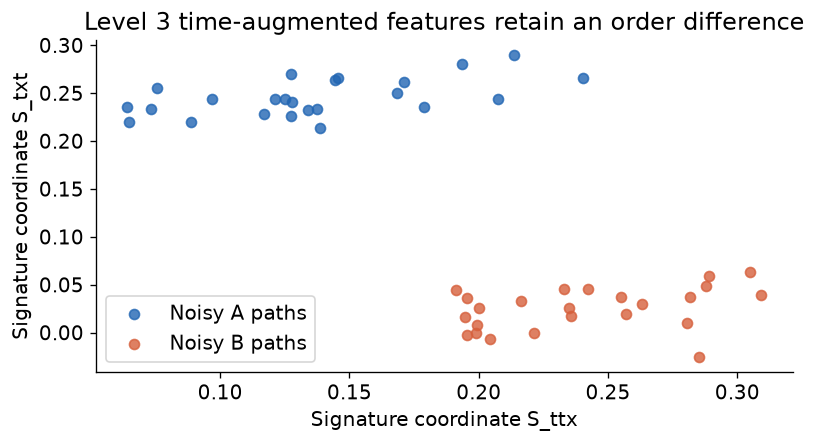

In [12]:
t_unit = t / 3
sig_a = signature_level3(np.c_[t_unit, series_a])
sig_b = signature_level3(np.c_[t_unit, series_b])
features_a = np.array([signature_level3(np.c_[t_unit, p]) for p in paths_a])
features_b = np.array([signature_level3(np.c_[t_unit, p]) for p in paths_b])
print('Feature order: level 1, then flattened levels 2 and 3 (t before x)')
print('Levels 1 and 2 agree:', np.allclose(sig_a[:6], sig_b[:6]))
print('S_ttx: A=7/54, B=13/54:', sig_a[7], sig_b[7])
print('A:', np.round(sig_a, 4)); print('B:', np.round(sig_b, 4))
print('Signature-feature MMD squared:', mmd2_biased(features_a, features_b, bandwidth=.5))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.scatter(features_a[:, 7], features_a[:, 8], label='Noisy A paths', alpha=.8)
ax.scatter(features_b[:, 7], features_b[:, 8], label='Noisy B paths', alpha=.8)
ax.set(xlabel='Signature coordinate S_ttx', ylabel='Signature coordinate S_txt',
       title='Level 3 time-augmented features retain an order difference')
ax.legend(); savefig('signatures')
metrics['signatures'] = dict(a=sig_a.tolist(), b=sig_b.tolist(),
                            mmd2=mmd2_biased(features_a, features_b, .5))

## 11. Maximum mean discrepancy (MMD)
MMD compares kernel mean embeddings. For independent copies X,X'~P and
Y,Y'~Q, $\mathrm{MMD}^2=E[k(X,X')]+E[k(Y,Y')]-2E[k(X,Y)]$.
The Gaussian kernel is $k(x,y)=\exp(-\|x-y\|^2/(2\ell^2))$.
It is characteristic on Euclidean space: population MMD=0 iff P=Q.
The code uses the **biased V-statistic**, including diagonal terms:
$$\widehat{\mathrm{MMD}}_b^2=\frac{1}{n^2}\sum_{ij}k(x_i,x_j)
+\frac{1}{m^2}\sum_{ij}k(y_i,y_j)-\frac{2}{nm}\sum_{ij}k(x_i,y_j).$$
The unbiased U-statistic excludes within-sample diagonals, uses n(n-1)
and m(m-1), and can be negative. State which estimator you report.
A kernel bandwidth sets the scale of comparison. Raw MMD and Wasserstein
values have different meanings and should not be ranked against each other.
These are descriptive examples, not calibrated hypothesis tests.

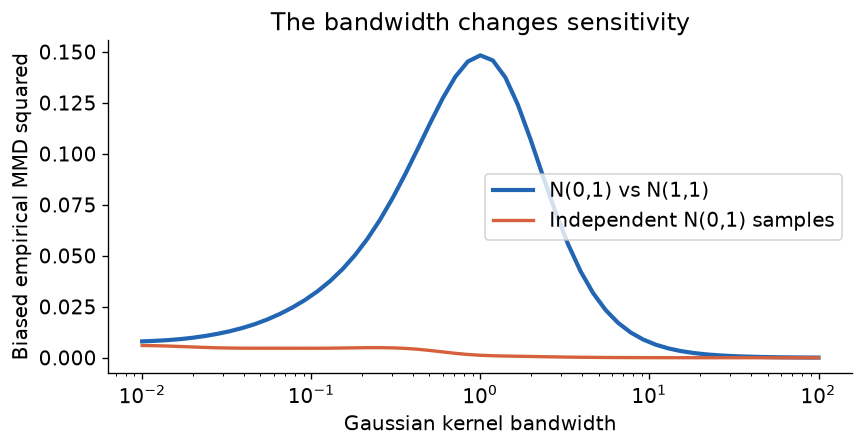

MMD squared on scalar amplitudes: 0.0
MMD squared on two-point windows: 0.06880805410941138
W1 on shifted Gaussian samples: 0.8837134629536747


In [13]:
x_mmd = path_rng.normal(size=300)
y_mmd = path_rng.normal(1, 1, 300)
x_mmd2 = path_rng.normal(size=300)
bandwidths = np.logspace(-2, 2, 55)
mmd_shift = [mmd2_biased(x_mmd, y_mmd, ell) for ell in bandwidths]
mmd_null = [mmd2_biased(x_mmd, x_mmd2, ell) for ell in bandwidths]
plt.figure(figsize=(8, 3.6))
plt.semilogx(bandwidths, mmd_shift, label='N(0,1) vs N(1,1)', lw=2.5)
plt.semilogx(bandwidths, mmd_null, label='Independent N(0,1) samples', lw=2)
plt.xlabel('Gaussian kernel bandwidth'); plt.ylabel('Biased empirical MMD squared')
plt.title('The bandwidth changes sensitivity'); plt.legend(); savefig('mmd')
print('MMD squared on scalar amplitudes:', mmd2_biased(series_a, series_b))
print('MMD squared on two-point windows:', mmd2_biased(windows_a, windows_b))
print('W1 on shifted Gaussian samples:', wasserstein_distance(x_mmd, y_mmd))

## 12. Multivariate Gaussians and generative models
For Gaussian laws N(m1,C1), N(m2,C2) with Euclidean ground distance,
$$W_2^2=\|m_1-m_2\|^2+\operatorname{tr}\left(C_1+C_2-
2(C_1^{1/2}C_2 C_1^{1/2})^{1/2}\right).$$
Matrix square roots are positive-semidefinite square roots, not elementwise
roots. If covariances commute, the covariance term is
$\|C_1^{1/2}-C_2^{1/2}\|_F^2$. Otherwise this shortcut is generally false.
FID uses this squared Gaussian formula after fitting moments in an image
feature space. It is not exact Wasserstein distance between raw image laws.
See Heusel et al. (2017), https://arxiv.org/abs/1706.08500 .

WGAN uses the W1 dual: sup over 1-Lipschitz f of E_P[f]-E_Q[f]. A trained
neural critic only approximates this optimization. The ordinary GAN lesson
in this repository is not a WGAN. Similarly, arbitrary learned flow matching
does not guarantee the minimum-cost transport coupling.
For generated series, compare independent real/real and real/generated
datasets in the same representation, and report temporal diagnostics too.

## 13. Student experiments
1. Change the target standard deviation from 2 to 3. Predict W2 first.
2. Change the bright patch's displacement to (2,1). Predict sqrt(5) pixels.
3. Multiply a whole image by 10. Explain which representation changes.
4. Permute a time series. Compare amplitudes, windows, whole paths, signatures.
5. Increase epsilon. Track cost, self cost, marginal residual, and plan density.
6. Use the same data with several MMD bandwidths. Explain the changed values.
See README.txt for answers and a suggested two-meeting teaching sequence.

## 14. Saved results and references
These tables come from this run. Rerunning regenerates slide data as well.

In [14]:
metrics['versions'] = dict(python=platform.python_version(), numpy=np.__version__,
                           scipy=scipy.__version__, matplotlib=matplotlib.__version__)
(ROOT / 'results' / 'metrics.json').write_text(json.dumps(metrics, indent=2) + '\n')
from refresh_slide_results import refresh
refresh(ROOT)
print('Saved figures, metrics.json, and slide tables in', ROOT)

Saved figures, metrics.json, and slide tables in /Users/munawarali/Documents/Research/DRP/Wasserstein Distance


Sources for the mathematical and computational background:
- Peyré and Cuturi, *Computational Optimal Transport*, sections 2, 3, 4, 8:
  https://arxiv.org/abs/1803.00567
- SciPy 1D W1 API: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html
- SciPy linear programming: https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html
- Cuturi, *Sinkhorn Distances* (2013): https://arxiv.org/abs/1306.0895
- Feydy et al., *Interpolating between OT and MMD using Sinkhorn Divergences*:
  https://proceedings.mlr.press/v89/feydy19a.html
- Gretton et al., *A Kernel Two-Sample Test* (2012): https://jmlr.org/papers/v13/gretton12a.html
- Chevyrev and Kormilitzin, *A Primer on the Signature Method in Machine Learning*:
  https://arxiv.org/abs/1603.03788
- Arjovsky et al., *Wasserstein GAN*: https://proceedings.mlr.press/v70/arjovsky17a.html
- POT production-oriented OT APIs: https://pythonot.github.io/all.html